
# Customer Churn Prediction — Interconnect

## Project Overview

Interconnect is a telecommunications company that provides landline and internet services. The company aims to reduce customer churn by identifying customers who are likely to discontinue their subscriptions.

The objective of this project is to develop a machine learning model capable of predicting customer churn and identifying the factors associated with customer cancellations.

### Project Objectives

- Combine customer information from multiple datasets.
- Perform data cleaning and exploratory data analysis (EDA).
- Prepare numerical and categorical features for machine learning.
- Train and compare classification models using cross-validation.
- Evaluate the final model on an independent test set.
- Identify relevant factors associated with customer churn.

### Data Description

The project uses four datasets:

- `contract.csv`: Contract information, payment methods, and charges.
- `personal.csv`: Customer demographic information.
- `internet.csv`: Internet services subscribed by each customer.
- `phone.csv`: Telephone service information.

### Methodology

1. Data loading and validation.
2. Data integration and preprocessing.
3. Exploratory data analysis.
4. Feature engineering.
5. Train-test split and stratified cross-validation.
6. Model training and hyperparameter optimization.
7. Final model evaluation and conclusions.

### Evaluation Metrics

The primary evaluation metric will be **ROC-AUC**.

Additional metrics will include:

- Recall
- Precision
- F1-score
- Confusion matrix

In [1]:
# Import libraries

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Model selection and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

# Model evaluation
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    classification_report,
    roc_curve,
    confusion_matrix
)

# General configuration
RANDOM_STATE = 12345

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [2]:
# Load the four datasets
contract  = pd.read_csv('/datasets/final_provider/contract.csv')
personal  = pd.read_csv('/datasets/final_provider/personal.csv')
internet  = pd.read_csv('/datasets/final_provider/internet.csv')
phone     = pd.read_csv('/datasets/final_provider/phone.csv')

# Display dataset dimensions and sample records
datasets = {
    "Contract": contract,
    "Personal": personal,
    "Internet": internet,
    "Phone": phone
}

for name, data in datasets.items():
    print(f"\n{name} Dataset")
    print(f"Shape: {data.shape}")
    display(data.head(3))


Contract Dataset
Shape: (7043, 8)


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15



Personal Dataset
Shape: (7043, 5)


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No



Internet Dataset
Shape: (5517, 8)


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No



Phone Dataset
Shape: (6361, 2)


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No


In [3]:
# Inspect dataset information and missing values

for name, data in datasets.items():
    print(f"\n{name} Dataset")

    print("\nDataset Information:")
    data.info()

    print("\nMissing Values:")
    print(data.isnull().sum())

    print("\nDuplicate Rows:")
    print(data.duplicated().sum())


Contract Dataset

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

Missing Values:
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

Duplicate Rows:
0

Personal Dataset

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0

In [4]:
# Validate customer identifiers

for name, data in datasets.items():
    duplicate_ids = data["customerID"].duplicated().sum()

    print(f"{name}:")
    print(f"Number of customers: {data['customerID'].nunique()}")
    print(f"Duplicate customer IDs: {duplicate_ids}")
    print("-" * 40)

Contract:
Number of customers: 7043
Duplicate customer IDs: 0
----------------------------------------
Personal:
Number of customers: 7043
Duplicate customer IDs: 0
----------------------------------------
Internet:
Number of customers: 5517
Duplicate customer IDs: 0
----------------------------------------
Phone:
Number of customers: 6361
Duplicate customer IDs: 0
----------------------------------------



### Initial Data Inspection

The initial inspection provides the following observations:

- The contract and personal datasets contain information for all 7,043 customers.
- The internet dataset contains 5,517 customer records.
- The phone dataset contains 6,361 customer records.
- The datasets use `customerID` as their common identifier.
- Some customers do not appear in the internet or phone datasets, which may indicate that they have not subscribed to those services.

Missing values and service availability will be examined further during the data integration and cleaning stages.

## Exploratory Data Analysis (EDA)

### Target variable: Customer Churn

The target variable `churn` indicates whether a customer discontinued the service.

- `1`: The customer left the company (`EndDate` contains a date).
- `0`: The customer is still active (`EndDate` is `"No"`).

This is a binary classification problem. Understanding the target distribution is important to identify potential class imbalance before training the models.

In [5]:
# Create the target variable
contract['churn'] = (contract['EndDate'] != 'No').astype(int)

# Display target distribution
churn_distribution = contract['churn'].value_counts().sort_index()

print("Target variable distribution:")
print(churn_distribution)

print(f"\nChurn rate: {contract['churn'].mean():.2%}")
print(f"Active customers: {(contract['churn'] == 0).sum():,}")
print(f"Churned customers: {(contract['churn'] == 1).sum():,}")

Target variable distribution:
0    5174
1    1869
Name: churn, dtype: int64

Churn rate: 26.54%
Active customers: 5,174
Churned customers: 1,869


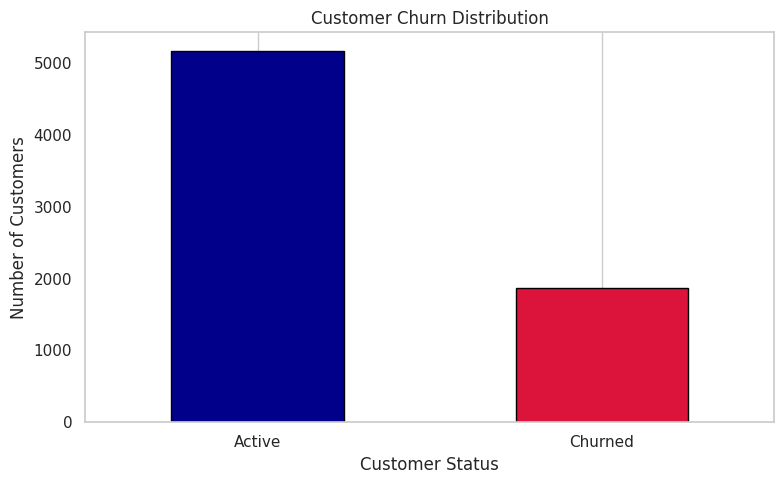

In [6]:
# Plot target variable distribution
plt.figure(figsize=(8, 5))

churn_distribution.plot(
    kind='bar',
    color=['darkblue', 'crimson'],
    edgecolor='black'
)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')
plt.xticks(
    ticks=[0, 1],
    labels=['Active', 'Churned'],
    rotation=0
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Target Distribution Analysis

The target variable shows an imbalance between active and churned customers. Most customers remain subscribed, while a smaller proportion have discontinued the service.

This class distribution will be considered during model evaluation. In addition to ROC-AUC, we will analyze Recall, Precision, and F1-score to understand how effectively each model identifies customers at risk of leaving.

### Data Preparation and Feature Engineering

Before combining the datasets, we will transform date columns and create a customer tenure feature.

The reference date is February 1, 2020, which represents the dataset's observation cutoff. Using a fixed date ensures that tenure is calculated consistently and avoids introducing information from outside the original observation period.

In [7]:
# Convert date columns
contract['BeginDate'] = pd.to_datetime(
    contract['BeginDate'],
    errors='coerce'
)

contract['EndDate'] = pd.to_datetime(
    contract['EndDate'],
    errors='coerce'
)

# Define the observation cutoff date
REFERENCE_DATE = pd.Timestamp('2020-02-01')

# Calculate customer tenure in days
contract['tenure_days'] = (
    REFERENCE_DATE - contract['BeginDate']
).dt.days

# Check the resulting feature
print("Customer tenure statistics:")
print(contract['tenure_days'].describe())

print("\nMissing tenure values:")
print(contract['tenure_days'].isna().sum())

Customer tenure statistics:
count    7043.000000
mean     1006.457050
std       736.596428
min         0.000000
25%       306.000000
50%       883.000000
75%      1706.000000
max      2314.000000
Name: tenure_days, dtype: float64

Missing tenure values:
0


In [8]:
# Convert charge columns to numeric
contract['TotalCharges'] = pd.to_numeric(
    contract['TotalCharges'],
    errors='coerce'
)

contract['MonthlyCharges'] = pd.to_numeric(
    contract['MonthlyCharges'],
    errors='coerce'
)

# Inspect missing TotalCharges values
missing_total_charges = contract[
    contract['TotalCharges'].isna()
]

print("Missing TotalCharges records:")
print(
    missing_total_charges[
        ['customerID', 'BeginDate', 'MonthlyCharges', 'TotalCharges', 'tenure_days']
    ]
)

print(
    f"\nNumber of missing TotalCharges values: "
    f"{contract['TotalCharges'].isna().sum()}"
)

Missing TotalCharges records:
      customerID  BeginDate  MonthlyCharges  TotalCharges  tenure_days
488   4472-LVYGI 2020-02-01           52.55           NaN            0
753   3115-CZMZD 2020-02-01           20.25           NaN            0
936   5709-LVOEQ 2020-02-01           80.85           NaN            0
1082  4367-NUYAO 2020-02-01           25.75           NaN            0
1340  1371-DWPAZ 2020-02-01           56.05           NaN            0
3331  7644-OMVMY 2020-02-01           19.85           NaN            0
3826  3213-VVOLG 2020-02-01           25.35           NaN            0
4380  2520-SGTTA 2020-02-01           20.00           NaN            0
5218  2923-ARZLG 2020-02-01           19.70           NaN            0
6670  4075-WKNIU 2020-02-01           73.35           NaN            0
6754  2775-SEFEE 2020-02-01           61.90           NaN            0

Number of missing TotalCharges values: 11


In [9]:
# Replace missing TotalCharges values with zero
contract['TotalCharges'] = contract['TotalCharges'].fillna(0)

# Verify numerical columns
print("Missing values after cleaning:")
print(
    contract[['MonthlyCharges', 'TotalCharges', 'tenure_days']]
    .isna()
    .sum()
)

Missing values after cleaning:
MonthlyCharges    0
TotalCharges      0
tenure_days       0
dtype: int64


In [10]:
# Check customerID uniqueness in each dataset
datasets = {
    'contract': contract,
    'personal': personal,
    'internet': internet,
    'phone': phone
}

for name, data in datasets.items():
    duplicate_count = data['customerID'].duplicated().sum()

    print(
        f"{name}: {duplicate_count} duplicated customer IDs "
        f"out of {len(data)} records"
    )

contract: 0 duplicated customer IDs out of 7043 records
personal: 0 duplicated customer IDs out of 7043 records
internet: 0 duplicated customer IDs out of 5517 records
phone: 0 duplicated customer IDs out of 6361 records


In [11]:
# Merge datasets using customerID
df = contract.merge(
    personal,
    on='customerID',
    how='left',
    validate='one_to_one'
)

df = df.merge(
    internet,
    on='customerID',
    how='left',
    validate='one_to_one'
)

df = df.merge(
    phone,
    on='customerID',
    how='left',
    validate='one_to_one'
)

# Display merged dataset information
print(f"Dataset shape after merging: {df.shape}")

print("\nMissing values by column:")
print(
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .loc[lambda x: x > 0]
)

Dataset shape after merging: (7043, 22)

Missing values by column:
EndDate             5174
StreamingMovies     1526
StreamingTV         1526
TechSupport         1526
DeviceProtection    1526
OnlineBackup        1526
OnlineSecurity      1526
InternetService     1526
MultipleLines        682
dtype: int64


In [12]:
# Identify service-related columns
service_columns = [
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'MultipleLines'
]

# Replace missing service values
df[service_columns] = df[service_columns].fillna('No')

# Check remaining missing values
missing_values = df.isna().sum()

print("Remaining missing values:")
print(missing_values[missing_values > 0])

print(f"\nTotal remaining missing values: {df.isna().sum().sum()}")

Remaining missing values:
EndDate    5174
dtype: int64

Total remaining missing values: 5174


In [13]:
# Remove identifiers and original date columns
columns_to_drop = [
    'customerID',
    'BeginDate',
    'EndDate'
]

df = df.drop(columns=columns_to_drop)

# Separate target and features
X = df.drop(columns='churn')
y = df['churn']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(3))

Features shape: (7043, 18)
Target shape: (7043,)

Feature columns:
['Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'tenure_days', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']

Target distribution:
0    0.735
1    0.265
Name: churn, dtype: float64


In [14]:
# Validate final dataset
print("Final dataset information:")
print(X.info())

print("\nMissing values in features:")
print(X.isna().sum()[X.isna().sum() > 0])

print("\nDuplicate records:")
print(X.duplicated().sum())

print("\nNumerical features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include=['object', 'category']).columns.tolist())

Final dataset information:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Type              7043 non-null   object 
 1   PaperlessBilling  7043 non-null   object 
 2   PaymentMethod     7043 non-null   object 
 3   MonthlyCharges    7043 non-null   float64
 4   TotalCharges      7043 non-null   float64
 5   tenure_days       7043 non-null   int64  
 6   gender            7043 non-null   object 
 7   SeniorCitizen     7043 non-null   int64  
 8   Partner           7043 non-null   object 
 9   Dependents        7043 non-null   object 
 10  InternetService   7043 non-null   object 
 11  OnlineSecurity    7043 non-null   object 
 12  OnlineBackup      7043 non-null   object 
 13  DeviceProtection  7043 non-null   object 
 14  TechSupport       7043 non-null   object 
 15  StreamingTV       7043 non-null   object 
 16  StreamingMovies

## Exploratory Data Analysis

### Numerical Features Analysis

This section explores the distribution of numerical variables and their relationship with customer churn. The analysis focuses on customer tenure, monthly charges, and total charges.

In [15]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

print("Numerical features:")
print(numerical_features)

X[numerical_features].describe().T

Numerical features:
['MonthlyCharges', 'TotalCharges', 'tenure_days', 'SeniorCitizen']


,count,mean,std,min,25%,50%,75%,max
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
tenure_days,7043.0,1006.457050,736.596428,0.00,306.00,883.00,1706.00,2314.00
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00


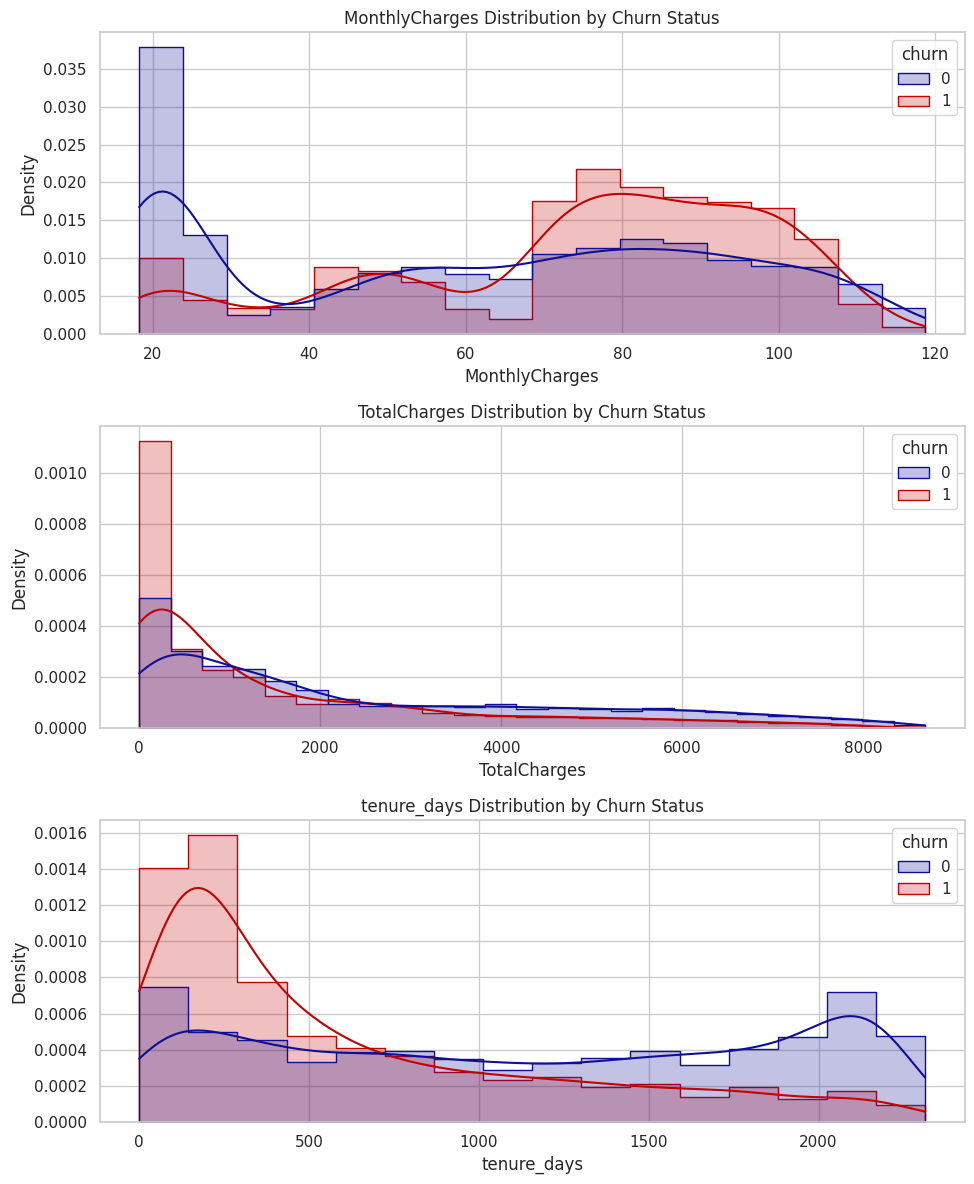

In [60]:
continuous_features = [
    feature for feature in numerical_features
    if X[feature].nunique() > 2
]

fig, axes = plt.subplots(
    nrows=len(continuous_features),
    ncols=1,
    figsize=(10, 4 * len(continuous_features))
)

if len(continuous_features) == 1:
    axes = [axes]

for ax, feature in zip(axes, continuous_features):
    sns.histplot(
        data=df,
        x=feature,
        hue='churn',
        kde=True,
        stat='density',
        common_norm=False,
        element='step',
        ax=ax,
        palette=['#0F0F96', '#C40000']
    )
    ax.set_title(f'{feature} Distribution by Churn Status')
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

### Categorical Features Analysis

This section examines the relationship between categorical customer characteristics, subscribed services, and churn. Churn rates are calculated for each category to identify groups with potentially higher cancellation rates.

In [24]:
categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

categorical_features.append('SeniorCitizen')

print("Categorical features:")
print(categorical_features)

print(f"\nNumber of categorical features: {len(categorical_features)}")

Categorical features:
['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines', 'SeniorCitizen']

Number of categorical features: 15


In [25]:
churn_rates = {}

for feature in categorical_features:
    churn_rate = (
        df.groupby(feature, observed=False)['churn']
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    churn_rates[feature] = churn_rate

    print(f"\n{feature}")
    print(churn_rate.round(2).astype(str) + '%')


Type
Type
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: churn, dtype: object

PaperlessBilling
PaperlessBilling
Yes    33.57%
No     16.33%
Name: churn, dtype: object

PaymentMethod
PaymentMethod
Electronic check             45.29%
Mailed check                 19.11%
Bank transfer (automatic)    16.71%
Credit card (automatic)      15.24%
Name: churn, dtype: object

gender
gender
Female    26.92%
Male      26.16%
Name: churn, dtype: object

Partner
Partner
No     32.96%
Yes    19.66%
Name: churn, dtype: object

Dependents
Dependents
No     31.28%
Yes    15.45%
Name: churn, dtype: object

InternetService
InternetService
Fiber optic    41.89%
DSL            18.96%
No               7.4%
Name: churn, dtype: object

OnlineSecurity
OnlineSecurity
No     31.33%
Yes    14.61%
Name: churn, dtype: object

OnlineBackup
OnlineBackup
No     29.17%
Yes    21.53%
Name: churn, dtype: object

DeviceProtection
DeviceProtection
No     28.65%
Yes     22.5%
Name: churn, d

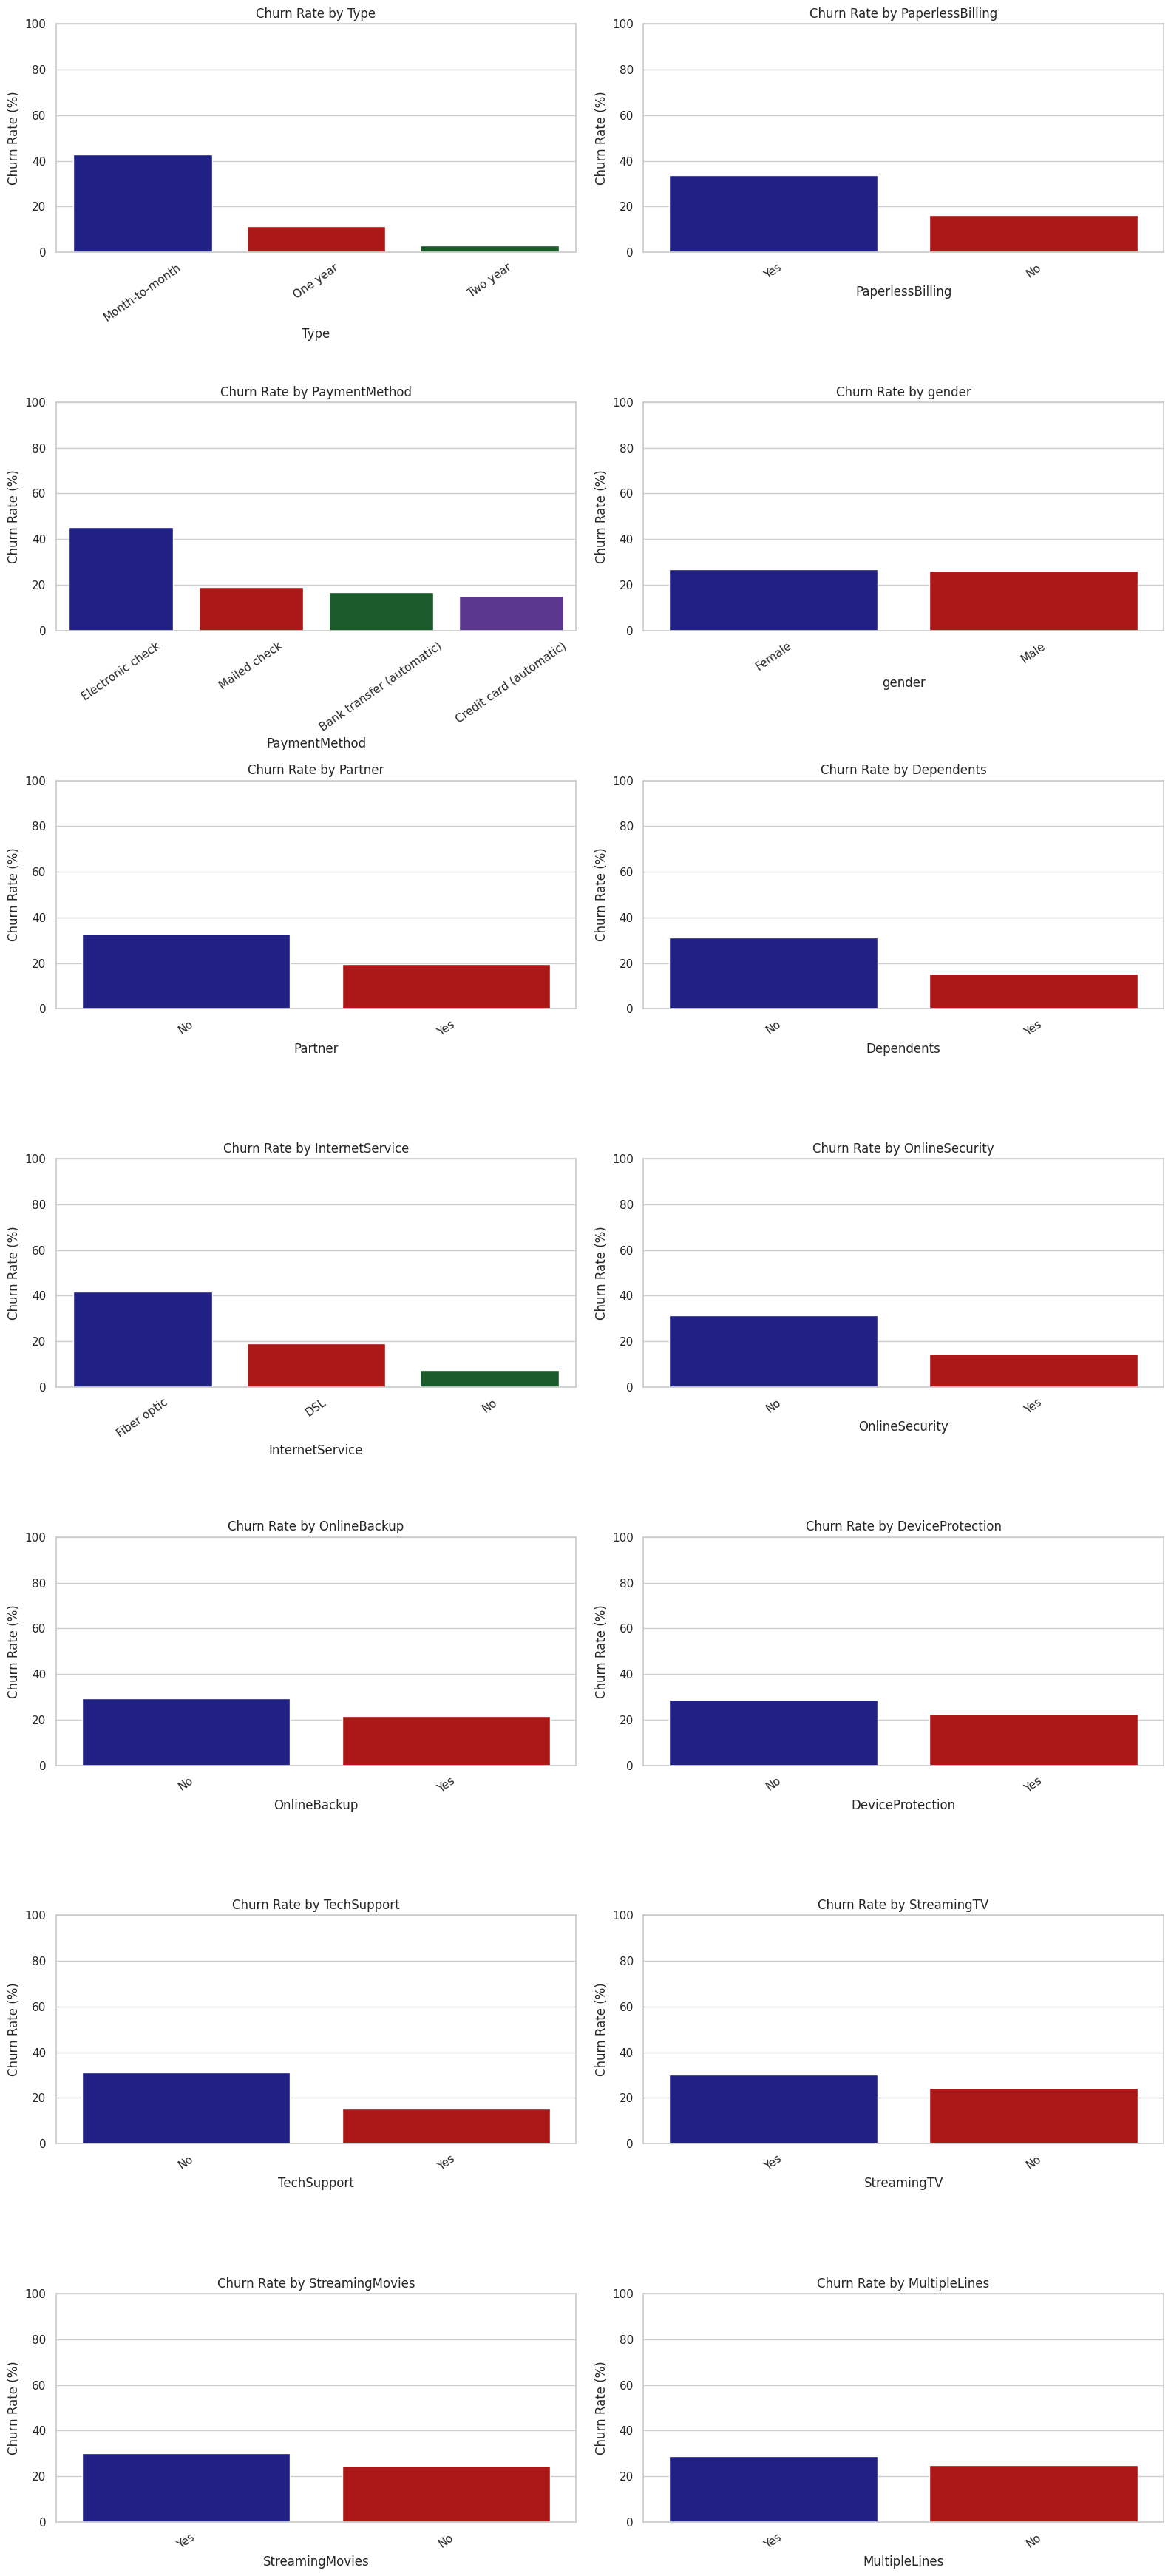

In [61]:
n_features = len(categorical_features)
n_cols = 2
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(16, 5 * n_rows)
)

axes = axes.flatten()

for ax, feature in zip(axes, categorical_features):
    rates = churn_rates[feature]

    sns.barplot(
        x=rates.index.astype(str),
        y=rates.values,
        ax=ax,
        palette=['#0F0F96', '#C40000', '#116424', '#592A9C']
    )

    ax.set_title(f'Churn Rate by {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Churn Rate (%)')
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylim(0, 100)

for ax in axes[n_features:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [27]:
category_summary = []

for feature in categorical_features:
    summary = (
        df.groupby(feature, dropna=False)['churn']
        .agg(
            customer_count='count',
            churn_rate='mean'
        )
        .reset_index()
        .rename(columns={feature: 'category'})
    )

    summary['feature'] = feature
    summary['churn_rate'] = summary['churn_rate'] * 100

    category_summary.append(summary)

category_summary = pd.concat(category_summary, ignore_index=True)

category_summary = category_summary[
    ['feature', 'category', 'customer_count', 'churn_rate']
]

category_summary['churn_rate'] = category_summary['churn_rate'].round(2)

category_summary.sort_values(
    by='churn_rate',
    ascending=False
)

,feature,category,customer_count,churn_rate
7,PaymentMethod,Electronic check,2365,45.29
0,Type,Month-to-month,3875,42.71
16,InternetService,Fiber optic,3096,41.89
33,SeniorCitizen,1,1142,41.68
4,PaperlessBilling,Yes,4171,33.57
11,Partner,No,3641,32.96
18,OnlineSecurity,No,5024,31.33
13,Dependents,No,4933,31.28
24,TechSupport,No,4999,31.19
27,StreamingTV,Yes,2707,30.07


### Exploratory Data Analysis Summary

The categorical analysis helps identify customer segments with different churn rates. However, these results are descriptive and do not establish causal relationships.

The number of customers in each category should also be considered when interpreting the results. Categories with a small number of observations may have less reliable churn rates.

Correlation between numerical features and churn:


,correlation
tenure_days,-0.311715
TotalCharges,-0.198324
MonthlyCharges,0.193356
SeniorCitizen,0.150889


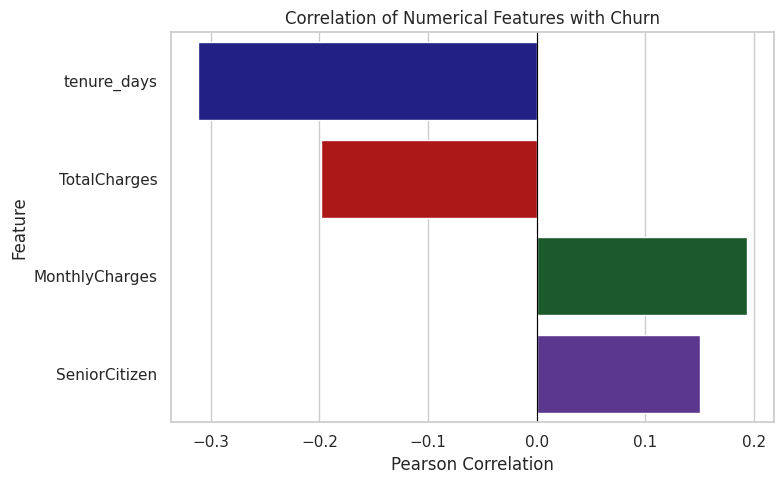

In [62]:
correlation_data = X.select_dtypes(include=np.number).copy()
correlation_data['churn'] = y

correlation_matrix = correlation_data.corr(method='pearson')

churn_correlations = (
    correlation_matrix['churn']
    .drop('churn')
    .sort_values(key=abs, ascending=False)
)

print("Correlation between numerical features and churn:")
display(churn_correlations.to_frame(name='correlation'))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_correlations.values,
    y=churn_correlations.index,
    palette=['#0F0F96', '#C40000', '#116424', '#592A9C']
)

plt.title('Correlation of Numerical Features with Churn')
plt.xlabel('Pearson Correlation')
plt.ylabel('Feature')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

### EDA Conclusions

The exploratory analysis provides an initial understanding of customer churn and the characteristics associated with it.

The main aspects to consider when developing predictive models are:

- The target variable is imbalanced, with fewer churned customers than active customers.
- Customer tenure and billing characteristics may provide useful predictive information.
- Contract types, payment methods, and subscribed services may reveal differences in churn rates across customer segments.
- The observed relationships are descriptive and must be evaluated through predictive modeling.

The next section prepares the data for model development. Preprocessing will be incorporated into machine learning pipelines to prevent data leakage during cross-validation.


## Data Preparation and Model Development

This section prepares the dataset for machine learning and establishes a consistent evaluation methodology.

The data will be divided into training and test sets using stratified sampling. Preprocessing operations will be included within machine learning pipelines to prevent data leakage during cross-validation.

Four classification algorithms will be evaluated:

- Logistic Regression
- Decision Tree
- Random Forest
- LightGBM

Model selection will be based primarily on ROC-AUC, while Recall, Precision, and F1-score will provide additional information about classification performance.


### Train-Test Split

The dataset is divided into training and test sets using an 80/20 split. Stratification preserves the original proportion of churned and active customers in both subsets.

The test set will remain untouched during model training and hyperparameter optimization. It will only be used for the final evaluation of the selected model.

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=12345,
    stratify=y
)

print(f"Training features: {X_train.shape}")
print(f"Test features: {X_test.shape}")

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 18)
Test features: (1409, 18)

Training target distribution:
0    0.735
1    0.265
Name: churn, dtype: float64

Test target distribution:
0    0.735
1    0.265
Name: churn, dtype: float64


### Feature Identification

Numerical and categorical features are identified separately to apply the appropriate preprocessing transformations.

Numerical variables will be imputed using the median. Categorical variables will be imputed using the most frequent value and encoded using One-Hot Encoding.

Scaling will be applied to numerical variables in the Logistic Regression pipeline. Tree-based models do not require feature scaling.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score,
    make_scorer
)

In [34]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print(f"Numerical features ({len(numeric_features)}):")
print(numeric_features)

print(f"\nCategorical features ({len(categorical_features)}):")
print(categorical_features)

print(
    f"\nTotal features: "
    f"{len(numeric_features) + len(categorical_features)}"
)

Numerical features (4):
['MonthlyCharges', 'TotalCharges', 'tenure_days', 'SeniorCitizen']

Categorical features (14):
['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']

Total features: 18


### Preprocessing Pipelines

Preprocessing is implemented through Scikit-learn's ColumnTransformer and Pipeline classes.

This approach ensures that imputation, scaling, and categorical encoding are fitted independently within each cross-validation training fold. It prevents information from validation folds from influencing the preprocessing process.

In [35]:
# Numerical preprocessing for Logistic Regression
numeric_transformer_scaled = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Numerical preprocessing for tree-based models
numeric_transformer_tree = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Preprocessor for Logistic Regression
preprocessor_logistic = ColumnTransformer(transformers=[
    ('num', numeric_transformer_scaled, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Preprocessor for tree-based models
preprocessor_tree = ColumnTransformer(transformers=[
    ('num', numeric_transformer_tree, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipelines successfully created.")

Preprocessing pipelines successfully created.



### Cross-Validation Strategy

Stratified 5-fold cross-validation is used to evaluate model configurations during hyperparameter optimization.

Each fold preserves approximately the same class distribution as the original training dataset. This provides a more robust basis for model comparison than relying on a single validation split.

ROC-AUC is selected as the primary optimization metric. Recall, Precision, and F1-score are also recorded to evaluate the models from different perspectives.


In [36]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=12345
)

scoring = {
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': 'precision',
    'f1': 'f1',
    'accuracy': 'accuracy'
}

print("Cross-validation strategy:")
print(cv_strategy)

print("\nEvaluation metrics:")
print(list(scoring.keys()))

Cross-validation strategy:
StratifiedKFold(n_splits=5, random_state=12345, shuffle=True)

Evaluation metrics:
['roc_auc', 'recall', 'precision', 'f1', 'accuracy']



### Handling Class Imbalance

The target variable contains fewer churned customers than active customers. Instead of applying artificial oversampling, the models will be evaluated using metrics that account for different aspects of classification performance.

Class weighting will also be considered for selected algorithms. This allows the models to assign different importance to each target class without generating synthetic or duplicated observations.

ROC-AUC will remain the primary metric for model selection, while Recall and F1-score will help assess the models' ability to identify customers who are likely to churn.


## Model Training and Hyperparameter Optimization

Four classification models are trained and optimized using GridSearchCV and stratified 5-fold cross-validation.

Hyperparameter selection is based on ROC-AUC. Recall, Precision, F1-score, and Accuracy are also recorded to provide a broader assessment of model performance.

The test set is not used during this process.


### Logistic Regression

Logistic Regression is used as a baseline classification model. It estimates the probability of customer churn based on a weighted combination of the input features.

The model is trained using scaled numerical variables and One-Hot Encoded categorical variables. Different regularization strengths and class-weight configurations are evaluated.


In [37]:
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_logistic),
    ('model', LogisticRegression(
        max_iter=2000,
        random_state=12345
    ))
])

logistic_param_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring=scoring,
    refit='roc_auc',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Logistic Regression configuration completed.")

Logistic Regression configuration completed.


In [38]:
logistic_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_search.best_params_)

print(f"\nBest cross-validation ROC-AUC: {logistic_search.best_score_:.4f}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Logistic Regression parameters:
{'model__C': 1, 'model__class_weight': None}

Best cross-validation ROC-AUC: 0.8387



### Decision Tree Classifier

Decision Tree is evaluated as a non-linear classification model. It identifies patterns by splitting the dataset according to feature values.

The optimization process evaluates different tree depths, minimum sample requirements, and class-weight configurations. These parameters help control model complexity and reduce overfitting.

In [39]:
tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_tree),
    ('model', DecisionTreeClassifier(random_state=12345))
])

tree_param_grid = {
    'model__max_depth': [3, 5, 7, None],
    'model__min_samples_split': [2, 10],
    'model__min_samples_leaf': [1, 5],
    'model__class_weight': [None, 'balanced']
}

tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    scoring=scoring,
    refit='roc_auc',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Decision Tree configuration completed.")

Decision Tree configuration completed.


In [40]:
tree_search.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(tree_search.best_params_)

print(f"\nBest cross-validation ROC-AUC: {tree_search.best_score_:.4f}")

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Decision Tree parameters:
{'model__class_weight': None, 'model__max_depth': 7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}

Best cross-validation ROC-AUC: 0.8689



### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve predictive performance and reduce the variance associated with individual trees.

The hyperparameter search evaluates the number of trees, maximum tree depth, minimum leaf size, and class-weight configurations.


In [41]:
forest_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_tree),
    ('model', RandomForestClassifier(
        random_state=12345,
        n_jobs=1
    ))
])

forest_param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 3],
    'model__class_weight': [None, 'balanced']
}

forest_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=forest_param_grid,
    scoring=scoring,
    refit='roc_auc',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Random Forest configuration completed.")

Random Forest configuration completed.


In [42]:
forest_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(forest_search.best_params_)

print(f"\nBest cross-validation ROC-AUC: {forest_search.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest parameters:
{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}

Best cross-validation ROC-AUC: 0.8724



### LightGBM Classifier

LightGBM is a gradient boosting algorithm that builds decision trees sequentially, with each new tree attempting to improve the predictions made by the previous ones.

It is included to evaluate whether gradient boosting can identify customer churn patterns more effectively than the other classification algorithms.

The search evaluates the number of estimators, learning rate, maximum depth, number of leaves, and class-weight configurations.


In [44]:
try:
    from lightgbm import LGBMClassifier
    LIGHTGBM_AVAILABLE = True
    print("LightGBM is available.")
except ImportError:
    LIGHTGBM_AVAILABLE = False
    print("LightGBM is not installed in the current environment.")

lightgbm_search = None

if LIGHTGBM_AVAILABLE:
    lightgbm_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', LGBMClassifier(
            objective='binary',
            random_state=12345,
            n_jobs=1,
            verbosity=-1
        ))
    ])

    lightgbm_param_grid = {
        'model__n_estimators': [200, 400],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth': [-1, 10],
        'model__num_leaves': [15, 31],
        'model__class_weight': [None, 'balanced']
    }

    lightgbm_search = GridSearchCV(
        estimator=lightgbm_pipeline,
        param_grid=lightgbm_param_grid,
        scoring=scoring,
        refit='roc_auc',
        cv=cv_strategy,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    lightgbm_search.fit(X_train, y_train)

    print("Best LightGBM parameters:")
    print(lightgbm_search.best_params_)

    print(
        f"\nBest cross-validation ROC-AUC: "
        f"{lightgbm_search.best_score_:.4f}"
    )

else:
    print("LightGBM was skipped because it is not installed.")

LightGBM is available.
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best LightGBM parameters:
{'model__class_weight': None, 'model__learning_rate': 0.1, 'model__max_depth': -1, 'model__n_estimators': 400, 'model__num_leaves': 15}

Best cross-validation ROC-AUC: 0.9356



### Cross-Validation Results Comparison

The optimized models are compared using their best cross-validation configurations.

The comparison includes the mean ROC-AUC, Recall, Precision, F1-score, and Accuracy across the five validation folds. The standard deviation of ROC-AUC is also reported to assess the consistency of model performance across folds.


In [45]:
model_searches = {
    'Logistic Regression': logistic_search,
    'Decision Tree': tree_search,
    'Random Forest': forest_search
}

if lightgbm_search is not None:
    model_searches['LightGBM'] = lightgbm_search

results = []

for model_name, search in model_searches.items():
    best_index = search.best_index_
    cv_results = search.cv_results_

    results.append({
        'Model': model_name,
        'ROC-AUC': cv_results['mean_test_roc_auc'][best_index],
        'ROC-AUC Std': cv_results['std_test_roc_auc'][best_index],
        'Recall': cv_results['mean_test_recall'][best_index],
        'Precision': cv_results['mean_test_precision'][best_index],
        'F1-Score': cv_results['mean_test_f1'][best_index],
        'Accuracy': cv_results['mean_test_accuracy'][best_index],
        'Best Parameters': search.best_params_
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

display(
    results_df.drop(columns='Best Parameters').round(4)
)

,Model,ROC-AUC,ROC-AUC Std,Recall,Precision,F1-Score,Accuracy
0,LightGBM,0.9356,0.0054,0.7017,0.8687,0.7760,0.8926
1,Random Forest,0.8724,0.0125,0.5686,0.7348,0.6408,0.8310
2,Decision Tree,0.8689,0.0144,0.6174,0.7334,0.6697,0.8388
3,Logistic Regression,0.8387,0.0184,0.5284,0.6512,0.5832,0.7998


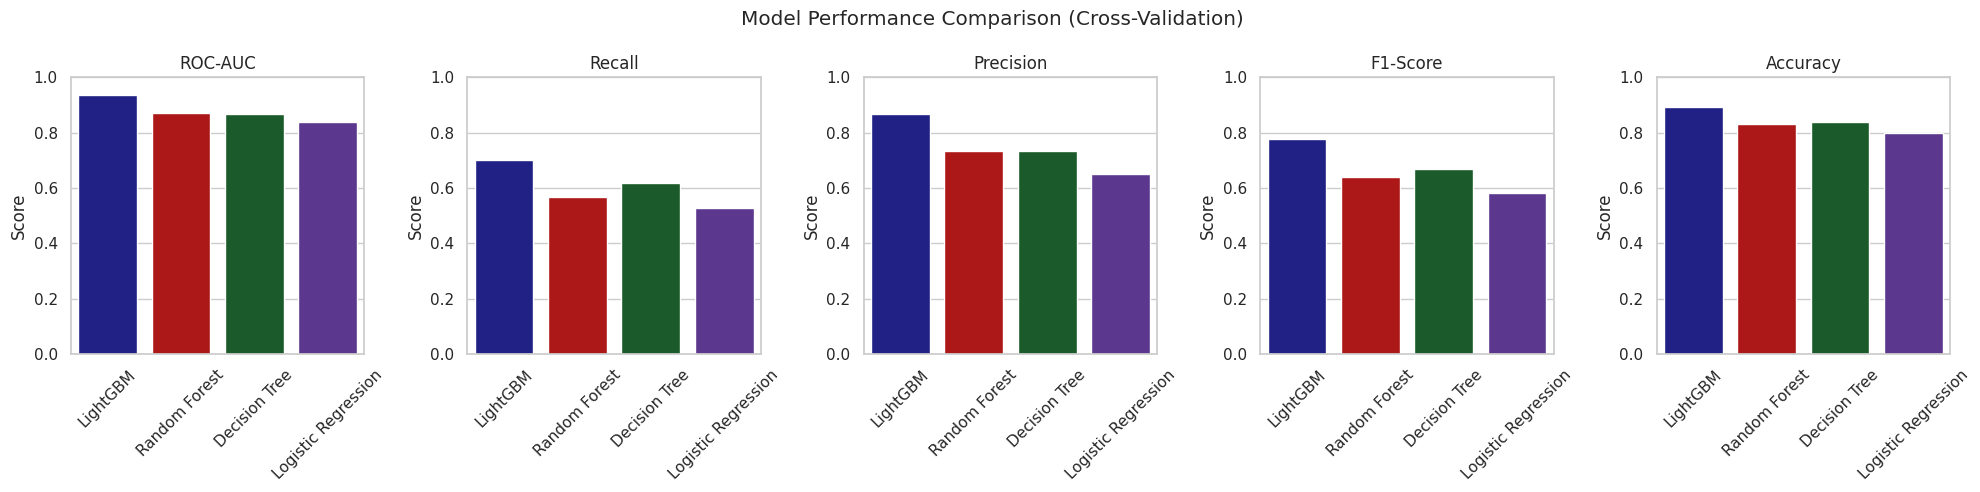

In [63]:
metrics_to_plot = [
    'ROC-AUC',
    'Recall',
    'Precision',
    'F1-Score',
    'Accuracy'
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(metrics_to_plot),
    figsize=(20, 5)
)

for ax, metric in zip(axes, metrics_to_plot):
    sns.barplot(
        data=results_df,
        x='Model',
        y=metric,
        ax=ax,
        palette=['#0F0F96', '#C40000', '#116424', '#592A9C']
    )

    ax.set_title(metric)
    ax.set_xlabel('')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Model Performance Comparison (Cross-Validation)')
plt.tight_layout()
plt.show()

In [47]:
for model_name, search in model_searches.items():
    print(f"\n{model_name}")
    print("-" * len(model_name))
    print(search.best_params_)


Logistic Regression
-------------------
{'model__C': 1, 'model__class_weight': None}

Decision Tree
-------------
{'model__class_weight': None, 'model__max_depth': 7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}

Random Forest
-------------
{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}

LightGBM
--------
{'model__class_weight': None, 'model__learning_rate': 0.1, 'model__max_depth': -1, 'model__n_estimators': 400, 'model__num_leaves': 15}



### Cross-Validation Results Analysis

The cross-validation results provide a consistent basis for comparing the four classification algorithms.

ROC-AUC is used as the primary model selection metric, while Recall, Precision, and F1-score provide additional insights into the models' ability to identify customers who are likely to churn.

The standard deviation of ROC-AUC across validation folds is also considered when assessing model stability.

The final model will be selected based on its overall cross-validation performance and its suitability for the customer churn prediction task.


### LightGBM Overfitting Assessment

The training and validation scores of the selected LightGBM configuration are compared to assess potential overfitting.

A substantial difference between training and validation performance may indicate that the model is learning patterns that do not generalize well to unseen data.


In [48]:
best_index = lightgbm_search.best_index_
cv_results = lightgbm_search.cv_results_

overfitting_assessment = pd.DataFrame({
    'Metric': ['ROC-AUC', 'Recall', 'Precision', 'F1-Score', 'Accuracy'],
    'Training Score': [
        cv_results['mean_train_roc_auc'][best_index],
        cv_results['mean_train_recall'][best_index],
        cv_results['mean_train_precision'][best_index],
        cv_results['mean_train_f1'][best_index],
        cv_results['mean_train_accuracy'][best_index]
    ],
    'Validation Score': [
        cv_results['mean_test_roc_auc'][best_index],
        cv_results['mean_test_recall'][best_index],
        cv_results['mean_test_precision'][best_index],
        cv_results['mean_test_f1'][best_index],
        cv_results['mean_test_accuracy'][best_index]
    ]
})

overfitting_assessment['Score Difference'] = (
    overfitting_assessment['Training Score']
    - overfitting_assessment['Validation Score']
)

display(overfitting_assessment.round(4))

,Metric,Training Score,Validation Score,Score Difference
0,ROC-AUC,0.9997,0.9356,0.0642
1,Recall,0.9676,0.7017,0.2659
2,Precision,0.9976,0.8687,0.1289
3,F1-Score,0.9823,0.7760,0.2063
4,Accuracy,0.9908,0.8926,0.0982



## Final Model Evaluation

The best LightGBM configuration selected through cross-validation is evaluated using the previously reserved test set.

The evaluation includes ROC-AUC, Recall, Precision, F1-score, Accuracy, and a confusion matrix. This provides an estimate of how the model performs on unseen customer data.

The default classification threshold of 0.5 is used for this initial evaluation.


In [49]:
from sklearn.metrics import classification_report, confusion_matrix

# Retrieve the best estimator, already refitted on the full training set
best_model = lightgbm_search.best_estimator_

# Generate predictions on the untouched test set
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

# Calculate final evaluation metrics
test_results = {
    'ROC-AUC': roc_auc_score(y_test, y_test_proba),
    'Recall': recall_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred),
    'F1-Score': f1_score(y_test, y_test_pred),
    'Accuracy': accuracy_score(y_test, y_test_pred)
}

test_results_df = pd.DataFrame(
    [test_results],
    index=['LightGBM']
)

print("Final Test Set Performance:")
display(test_results_df.round(4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=['Active', 'Churned'],
        digits=4
    )
)

Final Test Set Performance:


,ROC-AUC,Recall,Precision,F1-Score,Accuracy
LightGBM,0.9348,0.7219,0.8738,0.7906,0.8985



Classification Report:
              precision    recall  f1-score   support

      Active     0.9055    0.9623    0.9330      1035
     Churned     0.8738    0.7219    0.7906       374

    accuracy                         0.8985      1409
   macro avg     0.8896    0.8421    0.8618      1409
weighted avg     0.8970    0.8985    0.8952      1409



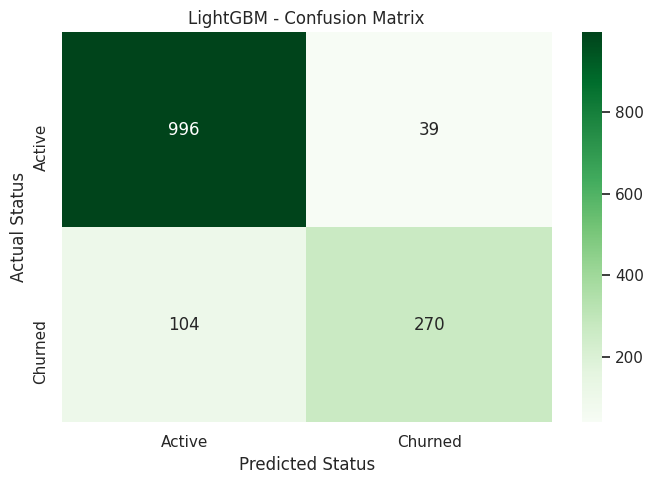

True Negatives: 996
False Positives: 39
False Negatives: 104
True Positives: 270


In [53]:
conf_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Active', 'Churned'],
    yticklabels=['Active', 'Churned']
)

plt.title('LightGBM - Confusion Matrix')
plt.xlabel('Predicted Status')
plt.ylabel('Actual Status')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = conf_matrix.ravel()

print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")

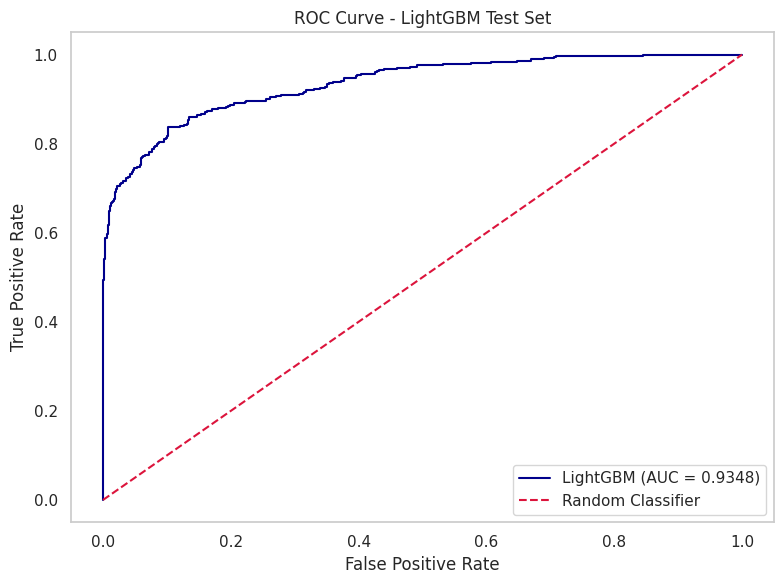

In [52]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
test_roc_auc = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'LightGBM (AUC = {test_roc_auc:.4f})',
    color='darkblue'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier',
    color='crimson'
)

plt.title('ROC Curve - LightGBM Test Set')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Model Interpretation

This section examines the contribution of customer features to the predictions made by the selected LightGBM model.

Permutation Feature Importance is used to estimate how much each feature contributes to predictive performance. The analysis is based on ROC-AUC and helps identify the variables that have the greatest influence on the model's ability to distinguish between active and churned customers.

Feature importance indicates predictive relevance, not causation.


In [64]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=12345,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': permutation_results.importances_mean,
    'Importance Std': permutation_results.importances_std
})

feature_importance = feature_importance.sort_values(
    by='Importance Mean',
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance Mean,Importance Std
0,TotalCharges,0.4743,0.0120
1,MonthlyCharges,0.2302,0.0076
2,tenure_days,0.2136,0.0117
3,Type,0.0357,0.0062
4,InternetService,0.0226,0.0030
5,PaymentMethod,0.0043,0.0012
6,MultipleLines,0.0025,0.0016
7,StreamingMovies,0.0010,0.0011
8,Partner,0.0006,0.0003
9,SeniorCitizen,0.0006,0.0005


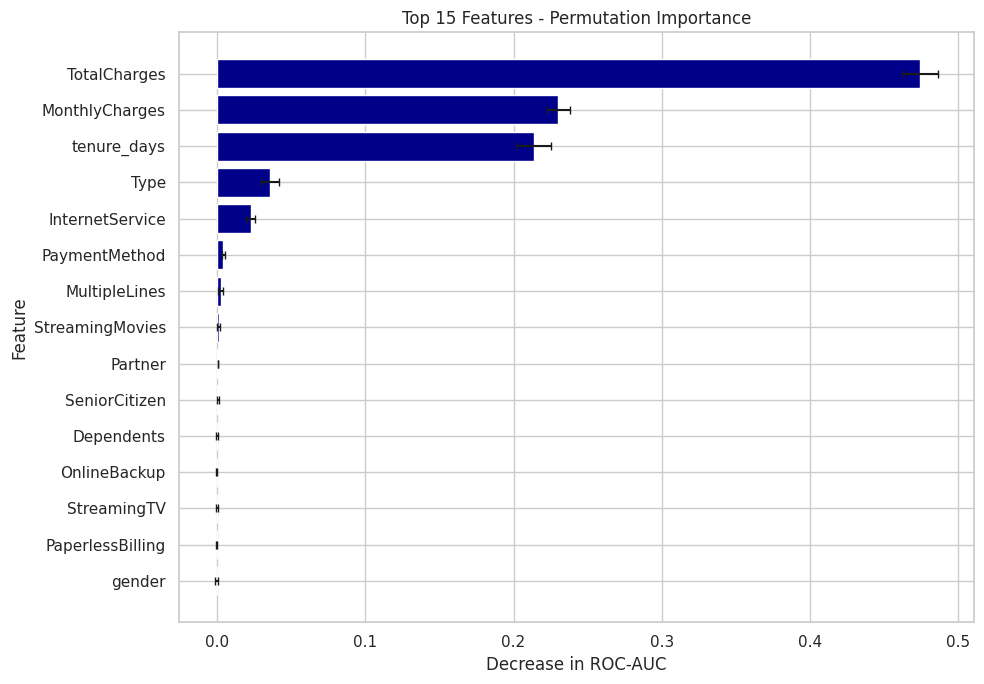

In [66]:
top_features = feature_importance.head(15).sort_values(
    by='Importance Mean',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance Mean'],
    xerr=top_features['Importance Std'],
    capsize=3,
    color='darkblue'
)

plt.title('Top 15 Features - Permutation Importance')
plt.xlabel('Decrease in ROC-AUC')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


## Classification Threshold Optimization

The default classification threshold of 0.5 is not necessarily the most suitable choice for customer churn prediction.

This section evaluates alternative thresholds to understand the trade-off between Recall and Precision.

Out-of-fold predictions generated through stratified cross-validation are used to select the threshold that maximizes the F1-score. The selected threshold is then evaluated on the reserved test set.

This approach avoids using test labels to optimize the classification threshold.


In [67]:
from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv_strategy,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated.")
print(f"Number of predictions: {len(oof_probabilities):,}")

Out-of-fold predictions generated.
Number of predictions: 5,634


In [68]:
thresholds_to_test = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds_to_test:
    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Recall': recall_score(y_train, oof_predictions),
        'Precision': precision_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        'F1-Score': f1_score(y_train, oof_predictions),
        'Accuracy': accuracy_score(y_train, oof_predictions)
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,Threshold,Recall,Precision,F1-Score,Accuracy
0,0.20,0.8548,0.6733,0.7533,0.8514
1,0.25,0.8308,0.7167,0.7695,0.8679
2,0.30,0.8107,0.7604,0.7847,0.8820
3,0.35,0.7826,0.7879,0.7852,0.8864
4,0.40,0.7605,0.8174,0.7879,0.8914
5,0.45,0.7291,0.8423,0.7816,0.8919
6,0.50,0.7017,0.8684,0.7762,0.8926
7,0.55,0.6709,0.8845,0.7630,0.8894
8,0.60,0.6455,0.9036,0.7530,0.8876
9,0.65,0.6201,0.9270,0.7431,0.8862


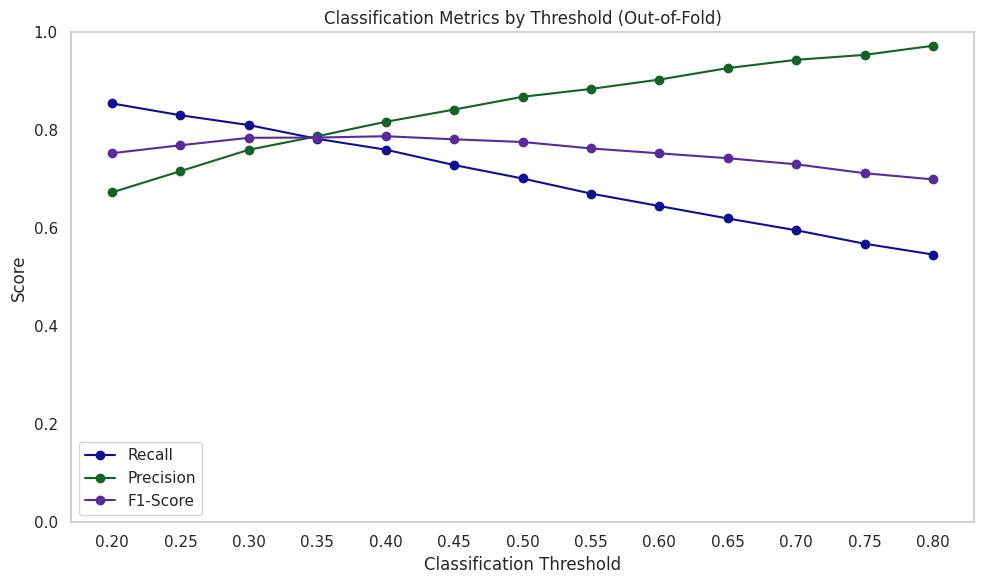

In [73]:
color_metric = {
    'Recall': '#0F0F96',     
    'Precision': '#116424',  
    'F1-Score': '#592A9C'    
}

plt.figure(figsize=(10, 6))

for metric in ['Recall', 'Precision', 'F1-Score']:
    plt.plot(
        threshold_results_df['Threshold'],
        threshold_results_df[metric],
        marker='o',
        label=metric,
        color=color_metric[metric]
    )

plt.title('Classification Metrics by Threshold (Out-of-Fold)')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.xticks(thresholds_to_test.round(2))
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [74]:
best_threshold_index = threshold_results_df['F1-Score'].idxmax()

best_threshold = threshold_results_df.loc[
    best_threshold_index,
    'Threshold'
]

print(f"Selected classification threshold: {best_threshold:.2f}")

print("\nPerformance at selected threshold:")
display(
    threshold_results_df.loc[
        [best_threshold_index]
    ].round(4)
)

Selected classification threshold: 0.40

Performance at selected threshold:


,Threshold,Recall,Precision,F1-Score,Accuracy
4,0.4,0.7605,0.8174,0.7879,0.8914


In [75]:
y_test_pred_tuned = (
    y_test_proba >= best_threshold
).astype(int)

tuned_test_results = {
    'ROC-AUC': roc_auc_score(y_test, y_test_proba),
    'Recall': recall_score(y_test, y_test_pred_tuned),
    'Precision': precision_score(y_test, y_test_pred_tuned),
    'F1-Score': f1_score(y_test, y_test_pred_tuned),
    'Accuracy': accuracy_score(y_test, y_test_pred_tuned)
}

threshold_comparison = pd.DataFrame(
    [
        {
            'Threshold': 0.50,
            **test_results
        },
        {
            'Threshold': best_threshold,
            **tuned_test_results
        }
    ],
    index=['Default Threshold', 'Optimized Threshold']
)

display(threshold_comparison.round(4))

,Threshold,ROC-AUC,Recall,Precision,F1-Score,Accuracy
Default Threshold,0.5,0.9348,0.7219,0.8738,0.7906,0.8985
Optimized Threshold,0.4,0.9348,0.7701,0.8205,0.7945,0.8943


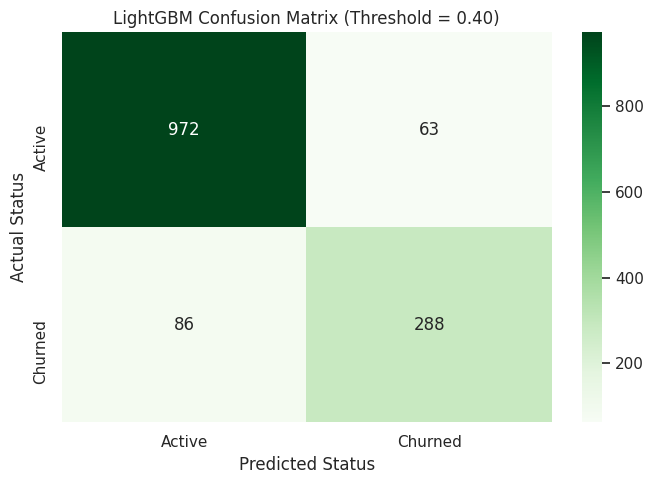

True Negatives: 972
False Positives: 63
False Negatives: 86
True Positives: 288


In [77]:
tuned_conf_matrix = confusion_matrix(
    y_test,
    y_test_pred_tuned
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    tuned_conf_matrix,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Active', 'Churned'],
    yticklabels=['Active', 'Churned']
)

plt.title(f'LightGBM Confusion Matrix (Threshold = {best_threshold:.2f})')
plt.xlabel('Predicted Status')
plt.ylabel('Actual Status')
plt.tight_layout()
plt.show()

tn_tuned, fp_tuned, fn_tuned, tp_tuned = tuned_conf_matrix.ravel()

print(f"True Negatives: {tn_tuned}")
print(f"False Positives: {fp_tuned}")
print(f"False Negatives: {fn_tuned}")
print(f"True Positives: {tp_tuned}")


### Threshold Optimization Analysis

The optimized classification threshold provides an alternative to the default 0.5 decision rule.

The comparison evaluates how changing the threshold affects Recall, Precision, F1-score, and Accuracy on the test set.

A lower threshold generally increases the number of customers classified as likely to churn, which can improve Recall while reducing Precision.

The final threshold should reflect the business objective and the relative costs of false positives and false negatives.



## Conclusions and Recommendations

### Model Performance

Four classification algorithms were evaluated using stratified 5-fold cross-validation: Logistic Regression, Decision Tree, Random Forest, and LightGBM.

LightGBM achieved the best cross-validation performance, with a ROC-AUC of 0.9356, Recall of 0.7017, Precision of 0.8687, and F1-score of 0.7760.

The selected model was subsequently evaluated on an independent test set, achieving:

- ROC-AUC: 0.9348
- Recall: 0.7219
- Precision: 0.8738
- F1-score: 0.7906
- Accuracy: 0.8985

The similarity between cross-validation and test ROC-AUC indicates that the model maintains consistent discrimination performance on unseen data.

The confusion matrix showed that the model correctly identified 270 out of 374 churned customers, while missing 104 cancellations.

Overall, LightGBM provided the strongest predictive performance among the evaluated models.


### Key Predictive Features

Permutation Feature Importance identified three variables as the strongest contributors to the model's predictive performance:

- TotalCharges: 0.4743
- MonthlyCharges: 0.2302
- tenure_days: 0.2136

Contract type and internet service also contributed to the predictions, although their importance was considerably lower.

These findings suggest that customer billing characteristics and tenure contain substantial information for distinguishing between active and churned customers.

However, feature importance measures predictive contribution rather than causal relationships. The relationship between total charges, monthly charges, and customer tenure should also be considered when interpreting these results.


### Classification Threshold Optimization

The default classification threshold of 0.5 was compared with an optimized threshold of 0.4, selected using out-of-fold predictions and F1-score.

On the test set, the threshold of 0.4 produced the following results:

- Recall increased from 0.7219 to 0.7701.
- Precision decreased from 0.8738 to 0.8205.
- F1-score increased from 0.7906 to 0.7945.
- Accuracy decreased from 0.8985 to 0.8943.

The optimized threshold identified 288 churned customers, compared with 270 using the default threshold. However, it also increased false positives from 39 to 63.

This demonstrates the trade-off between identifying more potential churn cases and avoiding unnecessary retention interventions.

The 0.4 threshold was selected as a more recall-oriented alternative, although the final business threshold should depend on the relative costs of false positives and false negatives.


### Business Implications

The results suggest that churn prediction models can support customer retention strategies by identifying customers who may be more likely to cancel their services.

Potential applications include:

- Prioritizing customers with higher predicted churn probabilities for retention campaigns.
- Designing targeted offers based on customer billing characteristics and subscribed services.
- Monitoring customer segments with different levels of churn risk.
- Allocating retention resources according to the probability of cancellation and the potential value of each customer.

The classification threshold can be adjusted according to the company's retention strategy. A lower threshold may be appropriate when missing a potential cancellation is more costly than contacting a customer who would have remained.

However, the model should be used as a decision-support tool rather than as an automatic replacement for business judgment.


### Limitations

Several limitations should be considered when interpreting the results:

- **Class imbalance:** Churned customers represent a smaller proportion of the dataset, which makes Recall and other class-specific metrics particularly important.
- **Potential overfitting:** The training scores were substantially higher than the cross-validation scores for some metrics, indicating that the model fits the training data more closely than unseen observations.
- **Historical data:** The dataset represents a historical snapshot, and its patterns may not fully reflect current customer behavior.
- **Feature relationships:** Variables such as TotalCharges, MonthlyCharges, and customer tenure are related, which may affect feature importance interpretation.
- **Temporal limitations:** The target is derived from the customer's EndDate. Some available features may describe customer activity at or after the cancellation event. Therefore, the current evaluation demonstrates retrospective classification performance, but does not establish that the model can predict future cancellations using only information available before they occur.
- **No causal inference:** The model identifies predictive relationships but does not establish why customers cancel their services.

Future work should consider a temporal prediction framework, using a defined observation date and only information available at that date to predict cancellations within a subsequent period.


### Final Remarks

This project explored the development of machine learning models for customer churn classification using customer demographics, subscribed services, contract information, and billing characteristics.

Among the four evaluated algorithms, LightGBM achieved the strongest results, with a test ROC-AUC of 0.9348 and an F1-score of 0.7906.

The threshold optimization experiment also demonstrated how classification decisions can be adapted to prioritize churn detection, increasing Recall to 0.7701 with a threshold of 0.4.

The project provided practical experience in data integration, exploratory data analysis, feature engineering, preprocessing pipelines, cross-validation, hyperparameter optimization, model evaluation, and interpretation.

Overall, the results demonstrate the potential of machine learning techniques for customer churn analysis while highlighting the importance of temporal data availability and business context when translating predictive performance into practical decisions.


In [78]:
final_summary = pd.DataFrame({
    'Metric': [
        'Cross-Validation ROC-AUC',
        'Test ROC-AUC',
        'Test Recall (0.5)',
        'Test Precision (0.5)',
        'Test F1-Score (0.5)',
        'Test Accuracy (0.5)',
        'Test Recall (0.4)',
        'Test Precision (0.4)',
        'Test F1-Score (0.4)',
        'Test Accuracy (0.4)'
    ],
    'Value': [
        lightgbm_search.best_score_,
        test_results['ROC-AUC'],
        test_results['Recall'],
        test_results['Precision'],
        test_results['F1-Score'],
        test_results['Accuracy'],
        tuned_test_results['Recall'],
        tuned_test_results['Precision'],
        tuned_test_results['F1-Score'],
        tuned_test_results['Accuracy']
    ]
})

display(final_summary.round(4))

,Metric,Value
0,Cross-Validation ROC-AUC,0.9356
1,Test ROC-AUC,0.9348
2,Test Recall (0.5),0.7219
3,Test Precision (0.5),0.8738
4,Test F1-Score (0.5),0.7906
5,Test Accuracy (0.5),0.8985
6,Test Recall (0.4),0.7701
7,Test Precision (0.4),0.8205
8,Test F1-Score (0.4),0.7945
9,Test Accuracy (0.4),0.8943
